

## Цель ноутбука

Подобрать параметры Ridge, ElasticNet и LightGBM и проверить, дают ли они выигрыш относительно исходных настроек. Сначала фиксирую baseline и выбираю параметры только по dev-CV; после этого один раз сравниваю модели на holdout и разбираю ошибки.

## Данные и признаки

Подготовка повторяет `improvements.ipynb`: удаляю полные дубликаты, сортирую по дате и оставляю последние два месяца за пределами development-CV. `quartile_zone` в модель не входит.


In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from lightgbm import LGBMRegressor
from side_lib import DateGroupedTimeSeriesSplit, make_pipeline, evaluate_cv


In [2]:
df = pd.read_csv('df_train.csv')
df['date'] = pd.to_datetime(df['date'], errors='coerce')
assert df['date'].notna().all()
assert df['price'].notna().all() and (df['price'] > 0).all()
df = df.drop_duplicates().sort_values('date', kind='mergesort').reset_index(drop=True)
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
bool_features = [
    'has_basement', 'renovated', 'nice_view', 'perfect_condition',
    'single_floor', 'has_lavatory',
]
for col in bool_features:
    df[col] = df[col].astype(int)


In [3]:
month_period = df['date'].dt.to_period('M')
holdout_months = sorted(month_period.unique())[-2:]
holdout_mask = month_period.isin(holdout_months)
dev = df.loc[~holdout_mask].reset_index(drop=True)
dev_dates = dev['date'].reset_index(drop=True)
y_dev = dev['price'].reset_index(drop=True)
print(f'Development заканчивается {dev.date.max():%Y-%m-%d}.')

Development заканчивается 2015-03-31.


In [4]:
numeric_features = ['year', 'month', 'bedrooms', 'real_bathrooms', 'living_in_m2']
categorical_features = ['grade']
X_base = dev[numeric_features + bool_features + categorical_features].copy()
tscv = DateGroupedTimeSeriesSplit(dev_dates, n_splits=5)

## Точка отсчёта

Сначала считаю LinearRegression и LightGBM на одинаковых признаках и временных фолдах. Для LightGBM беру параметры из `baseline.ipynb`; это исходный уровень, который будущие варианты должны превзойти.


In [5]:
baseline_variants = {
    'LinearRegression': (
        make_pipeline(LinearRegression(), numeric_features, bool_features, categorical_features),
        X_base,
    ),
    'LightGBM': (
        make_pipeline(
            LGBMRegressor(n_estimators=100, random_state=42, verbosity=-1),
            numeric_features, bool_features, categorical_features,
        ),
        X_base,
    ),
}
baseline_summary, baseline_folds = evaluate_cv(
    baseline_variants, y_dev, dev_dates, tscv
)
display(baseline_summary.round(3))

,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,LightGBM,112141.633,3451.458,143579.126,3704.690,0.518,0.011
1,LinearRegression,114292.543,4623.642,144877.338,5780.748,0.509,0.025


## Ridge и ElasticNet

Проверю, уменьшит ли штраф ошибку по сравнению с LinearRegression. Стандартизую `price` внутри `TransformedTargetRegressor`, а сетку оценю на тех же пяти временных фолдах.

In [6]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from matplotlib import pyplot as plt

In [7]:
cv_folds = list(tscv.split(X_base))
alpha_values = np.logspace(-3, 4, 30)

def target_scaled_pipeline(model):
    return TransformedTargetRegressor(
        regressor=make_pipeline(model, numeric_features, bool_features, categorical_features),
        transformer=StandardScaler(),
    )

In [8]:
ridge_search = GridSearchCV(
    target_scaled_pipeline(Ridge()),
    {'regressor__model__alpha': alpha_values},
    scoring='neg_root_mean_squared_error', cv=cv_folds, n_jobs=-1,
)
elastic_search = GridSearchCV(
    target_scaled_pipeline(ElasticNet(max_iter=20000, random_state=42)),
    {'regressor__model__alpha': alpha_values,
     'regressor__model__l1_ratio': [0.2, 0.5, 0.8]},
    scoring='neg_root_mean_squared_error', cv=cv_folds, n_jobs=-1,
)

ridge_search.fit(X_base, y_dev)
_ = elastic_search.fit(X_base, y_dev)

In [9]:
def search_results(search, model_name):
    results = pd.DataFrame(search.cv_results_)
    results['model'] = model_name
    results['alpha'] = results['param_regressor__model__alpha'].astype(float)
    if model_name == 'Ridge':
        results['l1_ratio'] = '—'
    else:
        results['l1_ratio'] = results['param_regressor__model__l1_ratio'].astype(float).map('{:.1f}'.format)
    results['rmse_mean'] = -results['mean_test_score']
    results['rmse_std'] = results['std_test_score']
    return results

ridge_results = search_results(ridge_search, 'Ridge')
elastic_results = search_results(elastic_search, 'ElasticNet')
all_search_results = pd.concat([ridge_results, elastic_results], ignore_index=True)
top5 = all_search_results.nsmallest(5, 'rmse_mean')[
    ['model', 'alpha', 'l1_ratio', 'rmse_mean', 'rmse_std']
]
display(top5.round(3))

,model,alpha,l1_ratio,rmse_mean,rmse_std
32,ElasticNet,0.001,0.8,144799.821,5117.069
31,ElasticNet,0.001,0.5,144820.113,5130.820
35,ElasticNet,0.002,0.8,144821.606,5075.320
30,ElasticNet,0.001,0.2,144842.108,5144.666
34,ElasticNet,0.002,0.5,144853.080,5099.320


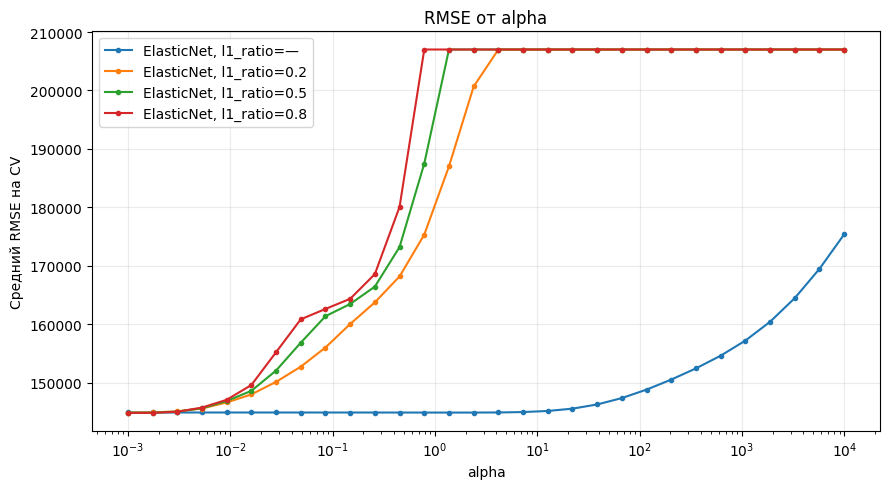

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
for model_name, results in [('Ridge', ridge_results), ('ElasticNet', elastic_results)]:
    for ratio, group in results.groupby('l1_ratio', dropna=False):
        label = model_name if pd.isna(ratio) else f'ElasticNet, l1_ratio={ratio}'
        group = group.sort_values('alpha')
        ax.plot(group['alpha'], group['rmse_mean'], marker='.', label=label)
ax.set_xscale('log')
ax.set(xlabel='alpha', ylabel='Средний RMSE на CV', title='RMSE от alpha')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
best_row = all_search_results.loc[all_search_results['rmse_mean'].idxmin()]
fold_scores = np.array([-best_row[f'split{i}_test_score'] for i in range(5)])
lr_folds = (baseline_folds[baseline_folds['variant'].eq('LinearRegression')]
            .sort_values('fold')['rmse'].to_numpy())
paired_gain = lr_folds - fold_scores
comparison = pd.DataFrame([
    {'model': 'LinearRegression', 'rmse_mean': lr_folds.mean(), 'rmse_std': lr_folds.std(ddof=1)},
    {'model': f"{best_row['model']} (лучший CV)", 'rmse_mean': fold_scores.mean(),
     'rmse_std': fold_scores.std(ddof=1)},
    {'model': 'Выигрыш по фолдам', 'rmse_mean': paired_gain.mean(),
     'rmse_std': paired_gain.std(ddof=1)},
])
display(comparison.round(3))
if abs(paired_gain.mean()) <= paired_gain.std(ddof=1):
    print('Среднее изменение RMSE укладывается в разброс разницы между фолдами.')
else:
    print('Среднее изменение RMSE больше разброса разницы между фолдами; результат всё равно основан на пяти фолдах.')

,model,rmse_mean,rmse_std
0,LinearRegression,144877.338,5780.748
1,ElasticNet (лучший CV),144799.821,5721.057
2,Выигрыш по фолдам,77.517,172.836


Среднее изменение RMSE укладывается в разброс разницы между фолдами.


Для регуляризации выбрана комбинация с минимальным средним RMSE на dev-CV. Поскольку эта же CV использовалась для выбора параметров, оценка лучшего варианта может быть немного оптимистичной; holdout остаётся нетронутым.

## LightGBM

Проверю 60 случайных наборов параметров на тех же пяти dev-фолдах. Отбираю по RMSE, а holdout оставляю нетронутым.

In [12]:
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV

In [13]:
lgbm_pipeline = make_pipeline(
    LGBMRegressor(random_state=42, subsample_freq=1, n_jobs=1, verbosity=-1),
    numeric_features, bool_features, categorical_features,
)
lgbm_params = {
    'model__num_leaves': randint(8, 65),
    'model__learning_rate': uniform(0.02, 0.08),
    'model__n_estimators': randint(100, 801),
    'model__min_child_samples': randint(10, 101),
    'model__subsample': uniform(0.6, 0.4),
    'model__colsample_bytree': uniform(0.6, 0.4),
    'model__reg_lambda': uniform(0, 10),
}

In [14]:
import warnings

lgbm_search = RandomizedSearchCV(
    lgbm_pipeline, lgbm_params, n_iter=60,
    scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
    refit='rmse', cv=cv_folds, random_state=42, n_jobs=-1,
)
with warnings.catch_warnings():
    warnings.filterwarnings(
        'ignore', message='X does not have valid feature names.*', category=UserWarning
    )
    _ = lgbm_search.fit(X_base, y_dev)

In [15]:
lgbm_cv = lgbm_search.cv_results_
top10 = pd.DataFrame({
    'num_leaves': lgbm_cv['param_model__num_leaves'],
    'learning_rate': lgbm_cv['param_model__learning_rate'],
    'n_estimators': lgbm_cv['param_model__n_estimators'],
    'min_child_samples': lgbm_cv['param_model__min_child_samples'],
    'subsample': lgbm_cv['param_model__subsample'],
    'colsample_bytree': lgbm_cv['param_model__colsample_bytree'],
    'reg_lambda': lgbm_cv['param_model__reg_lambda'],
    'subsample_freq': 1,
    'rmse_mean': -lgbm_cv['mean_test_rmse'],
    'rmse_std': np.std(
        np.vstack([-lgbm_cv[f'split{i}_test_rmse'] for i in range(5)]),
        axis=0, ddof=1,
    ),
    'r2_mean': lgbm_cv['mean_test_r2'],
})
top10 = top10.nsmallest(10, 'rmse_mean')
display(top10.round(3))

,num_leaves,learning_rate,n_estimators,min_child_samples,subsample,colsample_bytree,reg_lambda,subsample_freq,rmse_mean,rmse_std,r2_mean
11,32,0.031,164,24,0.909,0.817,9.869,1,142064.910,4032.108,0.528
45,36,0.031,138,57,0.768,0.939,2.965,1,142246.629,4272.336,0.526
7,43,0.023,180,87,0.902,0.798,1.822,1,142250.894,3902.524,0.526
24,56,0.032,180,65,0.764,0.885,9.766,1,142348.327,4355.368,0.526
48,32,0.055,150,72,0.993,0.832,1.550,1,142427.126,4525.743,0.525
17,11,0.071,195,61,0.700,0.613,9.076,1,142498.371,4609.736,0.525
56,19,0.024,552,71,0.905,0.646,0.172,1,142533.075,4703.052,0.525
2,40,0.020,376,69,0.810,0.975,3.042,1,142682.520,4457.157,0.524
13,14,0.094,127,50,0.780,0.842,8.500,1,142774.137,4684.339,0.523
12,24,0.020,598,20,0.916,0.679,7.113,1,142902.836,4548.382,0.522


In [16]:
best_index = lgbm_search.best_index_
tuned_rmse_folds = np.array([-lgbm_cv[f'split{i}_test_rmse'][best_index] for i in range(5)])
default_rmse_folds = (baseline_folds[baseline_folds['variant'].eq('LightGBM')]
                      .sort_values('fold')['rmse'].to_numpy())
fold_gain = default_rmse_folds - tuned_rmse_folds
lgbm_comparison = pd.DataFrame([
    {'вариант': 'LightGBM по умолчанию', 'RMSE mean': default_rmse_folds.mean(),
     'RMSE std': default_rmse_folds.std(ddof=1)},
    {'вариант': 'Лучший после поиска', 'RMSE mean': tuned_rmse_folds.mean(),
     'RMSE std': tuned_rmse_folds.std(ddof=1)},
    {'вариант': 'Выигрыш по фолдам', 'RMSE mean': fold_gain.mean(),
     'RMSE std': fold_gain.std(ddof=1)},
])
display(lgbm_comparison.round(3))
print(f"Средняя разница RMSE (дефолт минус лучший): {fold_gain.mean():,.0f}; std парной разницы: {fold_gain.std(ddof=1):,.0f}.".replace(",", " "))
if abs(fold_gain.mean()) <= fold_gain.std(ddof=1):
    print('Разница укладывается в разброс между фолдами.')
elif fold_gain.mean() > 0:
    print('Средний RMSE ниже дефолта больше, чем разброс разницы между фолдами.')
else:
    print('Средний RMSE выше дефолта больше, чем разброс разницы между фолдами.')

,вариант,RMSE mean,RMSE std
0,LightGBM по умолчанию,143579.126,3704.690
1,Лучший после поиска,142064.910,4032.108
2,Выигрыш по фолдам,1514.216,761.750


Средняя разница RMSE (дефолт минус лучший): 1 514; std парной разницы: 762.
Средний RMSE ниже дефолта больше, чем разброс разницы между фолдами.


Лучший LightGBM выбран из 60 вариантов на тех же dev-фолдах, поэтому его CV-оценка может быть оптимистичной. Второй круг поиска не запускал.

## Проверка устойчивости

Сравниваю RMSE на одинаковых фолдах. В таблице ниже показаны средние и стандартные отклонения парных разниц. Положительная разница означает, что во второй модели RMSE ниже.

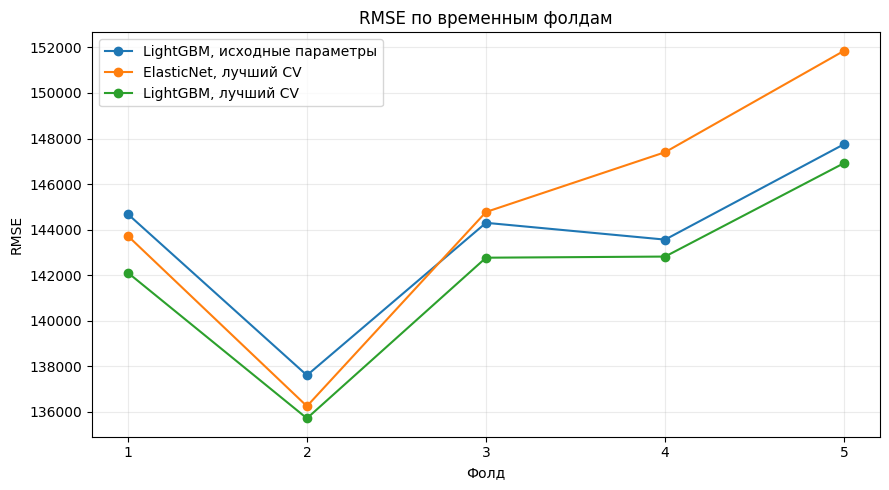

In [17]:
default_folds = (baseline_folds[baseline_folds['variant'].eq('LightGBM')]
                 .sort_values('fold')['rmse'].to_numpy())
best_linear_folds = np.array([-best_row[f'split{i}_test_score'] for i in range(5)])
best_lgbm_folds = np.array([-lgbm_cv[f'split{i}_test_rmse'][best_index] for i in range(5)])
fold_numbers = np.arange(1, 6)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(fold_numbers, default_folds, marker='o', label='LightGBM, исходные параметры')
ax.plot(fold_numbers, best_linear_folds, marker='o', label='ElasticNet, лучший CV')
ax.plot(fold_numbers, best_lgbm_folds, marker='o', label='LightGBM, лучший CV')
ax.set(xticks=fold_numbers, xlabel='Фолд', ylabel='RMSE', title='RMSE по временным фолдам')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
default_rmse = default_folds.mean()
stability_table = pd.DataFrame([
    {'model': 'LightGBM, исходные параметры', 'rmse_mean': default_rmse,
     'rmse_std': default_folds.std(ddof=1), 'gain_vs_default_pct': 0.0},
    {'model': 'ElasticNet, лучший CV', 'rmse_mean': best_linear_folds.mean(),
     'rmse_std': best_linear_folds.std(ddof=1),
     'gain_vs_default_pct': (default_rmse - best_linear_folds.mean()) / default_rmse * 100},
    {'model': 'LightGBM, лучший CV', 'rmse_mean': best_lgbm_folds.mean(),
     'rmse_std': best_lgbm_folds.std(ddof=1),
     'gain_vs_default_pct': (default_rmse - best_lgbm_folds.mean()) / default_rmse * 100},
])
display(stability_table.round(3))

,model,rmse_mean,rmse_std,gain_vs_default_pct
0,"LightGBM, исходные параметры",143579.126,3704.690,0.000
1,"ElasticNet, лучший CV",144799.821,5721.057,-0.850
2,"LightGBM, лучший CV",142064.910,4032.108,1.055


In [19]:
paired_model_diffs = pd.DataFrame([
    {'сравнение': 'LightGBM по умолчанию − лучший линейный',
     'разница_mean': (default_folds - best_linear_folds).mean(),
     'разница_std': (default_folds - best_linear_folds).std(ddof=1)},
    {'сравнение': 'LightGBM по умолчанию − лучший LightGBM',
     'разница_mean': (default_folds - best_lgbm_folds).mean(),
     'разница_std': (default_folds - best_lgbm_folds).std(ddof=1)},
    {'сравнение': 'Лучший линейный − лучший LightGBM',
     'разница_mean': (best_linear_folds - best_lgbm_folds).mean(),
     'разница_std': (best_linear_folds - best_lgbm_folds).std(ddof=1)},
])
paired_model_diffs['в пределах разброса'] = (
    paired_model_diffs['разница_mean'].abs() <= paired_model_diffs['разница_std']
)
display(paired_model_diffs.round(3))


,сравнение,разница_mean,разница_std,в пределах разброса
0,LightGBM по умолчанию − лучший линейный,-1220.695,2603.198,True
1,LightGBM по умолчанию − лучший LightGBM,1514.216,761.750,False
2,Лучший линейный − лучший LightGBM,2734.911,1929.020,False


## Holdout

Финальную модель выбираю по минимальному среднему RMSE на dev-CV среди лучшего линейного варианта, LightGBM с исходными параметрами и лучшего LightGBM из 60 проверенных вариантов. После этого обучаю варианты на всей dev-части и сравниваю метрики на последних двух месяцах. Holdout уже появлялся в ранних экспериментах, поэтому это проверка переноса во времени, а не независимая оценка.

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
holdout = df.loc[holdout_mask].reset_index(drop=True)
X_holdout = holdout[numeric_features + bool_features + categorical_features].copy()
y_holdout = holdout['price'].reset_index(drop=True)
print(f"Holdout: {holdout['date'].min():%Y-%m-%d} — {holdout['date'].max():%Y-%m-%d}, строк: {len(holdout)}")

Holdout: 2015-04-01 — 2015-05-14, строк: 1818


In [22]:
best_linear_name = f"{best_row['model']}, alpha={best_row['alpha']:.3g}"
if best_row['model'] == 'ElasticNet':
    best_linear_name += f", l1_ratio={float(best_row['l1_ratio']):.1f}"
    best_linear_pipeline = elastic_search.best_estimator_
else:
    best_linear_pipeline = ridge_search.best_estimator_

final_models = {
    'LinearRegression': make_pipeline(
        LinearRegression(), numeric_features, bool_features, categorical_features
    ),
    'LightGBM, исходные параметры': make_pipeline(
        LGBMRegressor(n_estimators=100, random_state=42, n_jobs=1, verbosity=-1),
        numeric_features, bool_features, categorical_features,
    ),
    best_linear_name: best_linear_pipeline,
    'LightGBM, лучший из 60': lgbm_search.best_estimator_,
}
final_cv_variants = {
    name: (model, X_base) for name, model in final_models.items()
}
final_cv_summary, _ = evaluate_cv(final_cv_variants, y_dev, dev_dates, tscv)
final_name = final_cv_summary.sort_values('rmse_mean').iloc[0]['variant']
display(final_cv_summary.round(3))
print(f'Финальная модель по минимальному среднему RMSE dev-CV: {final_name}.')

,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,"ElasticNet, alpha=0.001, l1_ratio=0.8",114389.108,4589.305,144799.821,5721.057,0.509,0.024
1,"LightGBM, исходные параметры",112141.633,3451.458,143579.126,3704.690,0.518,0.011
2,"LightGBM, лучший из 60",111628.893,3628.584,142064.910,4032.108,0.528,0.013
3,LinearRegression,114292.543,4623.642,144877.338,5780.748,0.509,0.025


Финальная модель по минимальному среднему RMSE dev-CV: LightGBM, лучший из 60.


In [23]:
holdout_predictions = {}
holdout_rows = []
for name, model in final_models.items():
    model.fit(X_base, y_dev)
    prediction = model.predict(X_holdout)
    holdout_predictions[name] = prediction
    holdout_rows.append({
        'model': name,
        'mae': mean_absolute_error(y_holdout, prediction),
        'rmse': mean_squared_error(y_holdout, prediction) ** 0.5,
        'r2': r2_score(y_holdout, prediction),
    })
holdout_metrics = pd.DataFrame(holdout_rows)
display(holdout_metrics.round(3))

,model,mae,rmse,r2
0,LinearRegression,122302.539,156930.036,0.424
1,"LightGBM, исходные параметры",119316.027,152940.335,0.453
2,"ElasticNet, alpha=0.001, l1_ratio=0.8",122371.657,156793.201,0.425
3,"LightGBM, лучший из 60",119145.288,152276.690,0.458


In [24]:
cv_rows = final_cv_summary.rename(columns={
    'variant': 'model', 'mae_mean': 'cv_mae', 'rmse_mean': 'cv_rmse', 'r2_mean': 'cv_r2'
})[['model', 'cv_mae', 'cv_rmse', 'cv_r2']]
cv_holdout_comparison = cv_rows.merge(holdout_metrics, on='model', how='left')
display(cv_holdout_comparison.round(3))

,model,cv_mae,cv_rmse,cv_r2,mae,rmse,r2
0,"ElasticNet, alpha=0.001, l1_ratio=0.8",114389.108,144799.821,0.509,122371.657,156793.201,0.425
1,"LightGBM, исходные параметры",112141.633,143579.126,0.518,119316.027,152940.335,0.453
2,"LightGBM, лучший из 60",111628.893,142064.910,0.528,119145.288,152276.690,0.458
3,LinearRegression,114292.543,144877.338,0.509,122302.539,156930.036,0.424


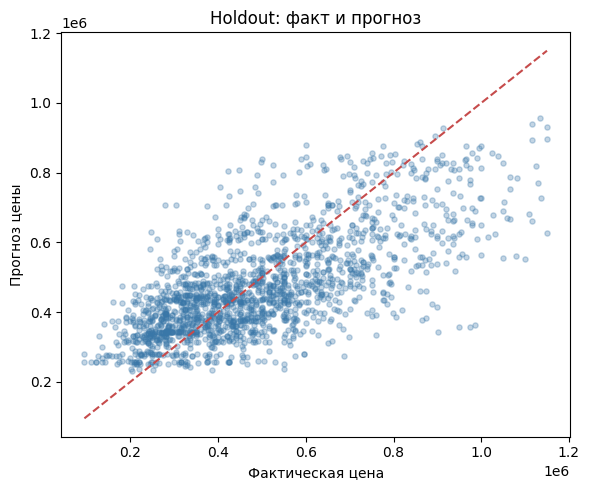

In [25]:
prediction = holdout_predictions[final_name]
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_holdout, prediction, alpha=0.3, s=14, color='#3977a8')
low = min(y_holdout.min(), prediction.min())
high = max(y_holdout.max(), prediction.max())
ax.plot([low, high], [low, high], '--', color='#c64b4b')
ax.set(title='Holdout: факт и прогноз', xlabel='Фактическая цена', ylabel='Прогноз цены')
plt.tight_layout()
plt.show()

Для выбранного LightGBM RMSE вырос с 142 065 по dev-CV до 152 277 на holdout, а R² снизился с 0,528 до 0,458. На holdout направление такое же и у остальных вариантов: RMSE выше, а R² ниже, чем на CV. Это показывает более слабое качество на позднем периоде, но не объясняет причину; holdout уже появлялся в ранних экспериментах.

## Где модель ошибается

Разберу ошибки выбранного LightGBM на holdout. Относительную ошибку считаю как абсолютную ошибку, делённую на фактическую цену; по группам посмотрю, где промахи крупнее.

In [26]:
final_prediction = holdout_predictions[final_name]
error_data = pd.DataFrame({
    'actual': y_holdout.to_numpy(),
    'prediction': final_prediction,
    'grade': holdout['grade'].to_numpy(),
})
error_data['residual'] = error_data['prediction'] - error_data['actual']
error_data['absolute_error'] = error_data['residual'].abs()
error_data['relative_error_pct'] = error_data['absolute_error'] / error_data['actual'] * 100
price_bins = pd.qcut(error_data['actual'], q=4, duplicates='drop')
error_data['price_quartile'] = [f'Q{i + 1}' for i in price_bins.cat.codes]

In [27]:
price_error = error_data.groupby('price_quartile', observed=True).agg(
    rows=('actual', 'size'), mae=('absolute_error', 'mean'),
    mean_relative_error_pct=('relative_error_pct', 'mean'),
).reset_index().rename(columns={'price_quartile': 'group'})
price_error.insert(0, 'group_type', 'Квартиль цены')
grade_error = error_data.groupby('grade', observed=True).agg(
    rows=('actual', 'size'), mae=('absolute_error', 'mean'),
    mean_relative_error_pct=('relative_error_pct', 'mean'),
).reset_index().rename(columns={'grade': 'group'})
grade_error.insert(0, 'group_type', 'Grade')
group_errors = pd.concat([price_error, grade_error], ignore_index=True)
display(group_errors.round(3))
holdout_mae_pct = error_data['absolute_error'].mean() / error_data['actual'].mean() * 100
print(f"Средняя цена holdout: {error_data['actual'].mean():,.0f}; MAE: {error_data['absolute_error'].mean():,.0f} ({holdout_mae_pct:.1f}% от средней цены).".replace(",", " "))

,group_type,group,rows,mae,mean_relative_error_pct
0,Квартиль цены,Q1,461,109872.255,45.065
1,Квартиль цены,Q2,448,79696.080,20.482
2,Квартиль цены,Q3,457,102735.061,19.474
3,Квартиль цены,Q4,452,184294.818,23.010
4,Grade,1,208,99651.061,31.953
5,Grade,2,808,112667.978,28.490
6,Grade,3,541,124777.725,25.371
7,Grade,4,193,150122.652,24.566
8,Grade,5,68,123008.330,16.444


Средняя цена holdout: 490 981; MAE: 119 145 (24.3% от средней цены).


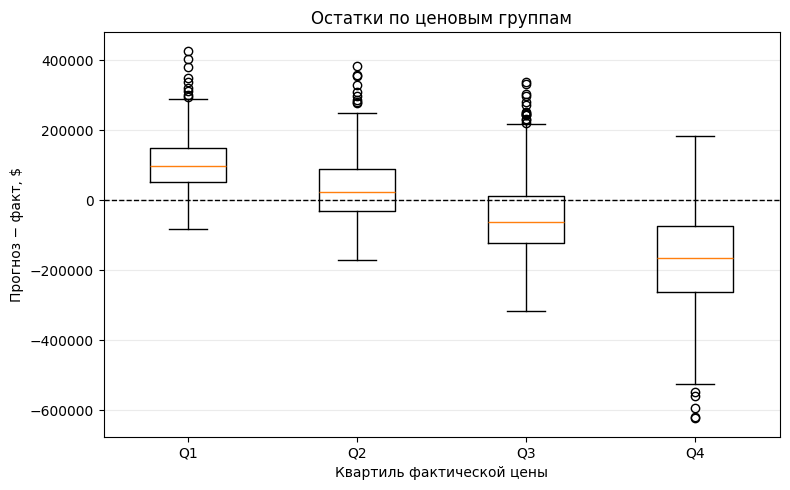

In [28]:
quartiles = sorted(error_data['price_quartile'].unique(), key=lambda value: int(value[1:]))
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([error_data.loc[error_data['price_quartile'].eq(q), 'residual'] for q in quartiles], tick_labels=quartiles)
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set(xlabel='Квартиль фактической цены', ylabel='Прогноз − факт, $', title='Остатки по ценовым группам')
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

,feature,mae_increase_mean,mae_increase_std
4,living_in_m2,29945.722,1412.842
11,grade,24169.171,1775.731
5,has_basement,5068.948,613.304
9,single_floor,3890.830,633.624
7,nice_view,3064.204,452.763
3,real_bathrooms,2300.798,339.364
8,perfect_condition,2117.673,682.945
6,renovated,1133.315,418.924
2,bedrooms,1123.951,259.250
10,has_lavatory,1103.918,164.880


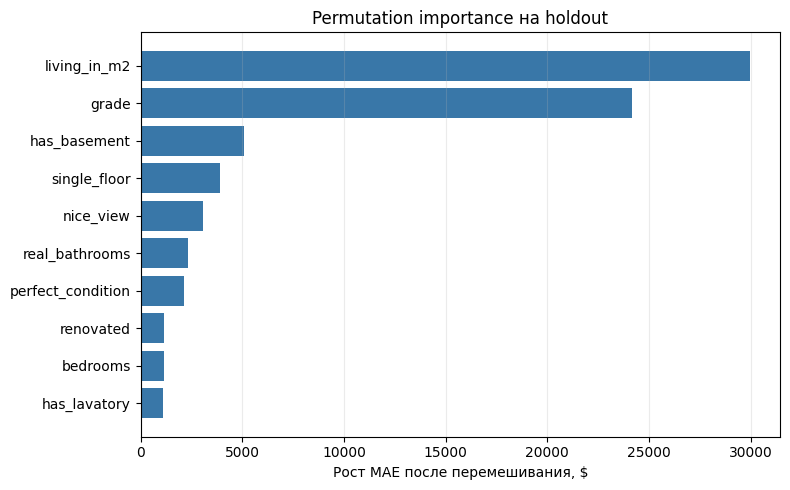

In [29]:
from sklearn.inspection import permutation_importance
importance_result = permutation_importance(
    final_models[final_name], X_holdout, y_holdout,
    scoring='neg_mean_absolute_error', n_repeats=10, random_state=42, n_jobs=-1,
)
importance = pd.DataFrame({
    'feature': X_holdout.columns,
    'mae_increase_mean': importance_result.importances_mean,
    'mae_increase_std': importance_result.importances_std,
}).sort_values('mae_increase_mean', ascending=False)
top_importance = importance.head(10).sort_values('mae_increase_mean')
display(importance.head(10).round(3))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_importance['feature'], top_importance['mae_increase_mean'], color='#3977a8')
ax.set(xlabel='Рост MAE после перемешивания, $', title='Permutation importance на holdout')
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

На holdout MAE составил 119 145 при средней цене 490 981, то есть 24,3% от средней цены. Это отношение среднего абсолютного промаха к средней цене; в таблице относительная ошибка считается отдельно для каждой сделки.

В долларах больше всего модель ошибалась в верхнем ценовом квартиле Q4: MAE 184 295. В процентах хуже всего нижний квартиль Q1: 45,1%. По grade наибольший MAE у grade 4 (150 123), а наибольшая относительная ошибка у grade 1 (32,0%).

Перемешивание living_in_m2 увеличило MAE в среднем на 29 946, а grade на 24 169. В этом holdout модель сильнее всего опирается на эти признаки; это не говорит о причинном влиянии признаков на цену.

## Выводы

Подбирал alpha для Ridge и ElasticNet и проверил 60 наборов параметров LightGBM на пяти dev-фолдах. Финальную модель выбрал по минимальному среднему RMSE на dev-CV: это LightGBM, лучший из 60 вариантов, со средним RMSE 142 065 против 143 579 у исходного LightGBM. Парная разница «исходный минус лучший» составила 1 514 при std 762; по этому правилу средний выигрыш превышает разброс разниц, но победитель выбран по тем же фолдам. Поэтому оценка лучшего LightGBM может быть оптимистичной.

Лучший alpha ElasticNet равен 0,001 и находится на нижней границе сетки. Его paired-разница RMSE с LinearRegression составила 78 при std 173, то есть линейные варианты практически не различаются на этих фолдах. У лучшего LightGBM `reg_lambda` равен 9,869 при верхней границе диапазона 10; второй круг поиска не проводил.

На holdout выбранный LightGBM получил MAE 119 145, RMSE 152 277 и R² 0,458. На CV его RMSE был 142 065, а R² 0,528; holdout уже участвовал в ранних экспериментах, поэтому это проверка переноса во времени, а не независимая оценка.

В абсолютных долларах модель хуже всего ошибалась в Q4, а в процентах от фактической цены в Q1. Permutation importance выше всего для living_in_m2 и grade. `quartile_zone` исключён из-за неизвестного способа расчёта; новые безопасные признаки и свежие данные могут быть полезнее следующего круга поиска.